# MLP 회귀 — 보스턴 주택 가격 예측 (PyTorch)

수업 필기 `MLP_보스톤_주택_가격_예측` 을 실행 가능하도록 정리 · 개선한 노트입니다.

- 📖 교재 : `딥러닝` 교재8 **p.86~89 · 91** (회귀 모델 설계 · `MSELoss` · 학습 루프 · MSE / RMSE 평가 · MLP 회귀 실습)
- 📝 메모 : `MLP_회귀_메모.pdf` (은닉층 구조 · MSE · Adam) → 수정본 `MLP_회귀_메모_수정본.txt`
- 🔗 앞 수업 : [Day 035 `mlp_titanic_binary.ipynb`](../../2026-10-28/lecture/mlp_titanic_binary.ipynb) (같은 틀의 **이진 분류**) — 오늘은 출력층 · 손실 함수 · 평가 지표만 바꿔 **회귀** 로
- 📝 고친 부분은 그 자리에 적고 맨 아래 표로 모았습니다. 🎬 애니메이션은 [`images/`](./images/) 폴더.

| | 어제 (타이타닉 · 이진 분류) | 오늘 (보스턴 · 회귀) |
|---|---|---|
| 정답 | 생존 0 / 1 | 집값 `medv` (천 달러, 5 ~ 50) |
| 출력층 | 뉴런 1 + 시그모이드 | 뉴런 1, **활성화 없음 (항등 함수)** |
| 손실 | `BCEWithLogitsLoss` | **`MSELoss`** |
| 평가 | 정확도 | **RMSE** (정답과 같은 단위) |

In [1]:
# 한글 폰트 설정 (Windows: Malgun Gothic / macOS: AppleGothic)
import platform
import matplotlib.pyplot as plt
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

## 1. 환경 설정

In [2]:
# 필요한 라이브러리 / 모듈 / 클래스 / 함수 임포트
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, r2_score   # sklearn 1.4 이상
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
torch.manual_seed(SEED)        # 가중치 초기값 · 미니배치 순서 고정 (재현성)
np.random.seed(SEED)

# 연산 디바이스: GPU 가 있으면 cuda, 없으면 cpu
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'사용 중인 디바이스: {device}')

사용 중인 디바이스: cpu


> **📝 고친 부분** — 주석 오타 `cput` → **cpu**. 쓰지 않는 `from torch.cuda import is_available` 삭제(아래에서 `torch.cuda.is_available()` 로 부름). 시드가 없어서 필기의 RMSE 4.1572 는 다시 돌리면 다른 값이 나온다 → `torch.manual_seed` 추가. `root_mean_squared_error` 는 **sklearn 1.4 이상** 에만 있다(예전 버전은 `mean_squared_error(..., squared=False)`).

## 2. 데이터 불러오기

보스턴 교외 506 개 지역의 1970 년대 주택 데이터. 정답 `medv` = 집값 중앙값(단위 **천 달러**).

| 컬럼 | 뜻 | 컬럼 | 뜻 |
|---|---|---|---|
| `crim` | 1 인당 범죄율 | `rad` | 고속도로 접근성 지수 |
| `zn` | 큰 주거지(2.5만 ft² 초과) 비율 | `tax` | 재산세율 |
| `indus` | 비소매 상업 지역 비율 | `ptratio` | 학생 / 교사 비율 |
| `chas` | 찰스강 접함 1 / 아님 0 | `b` | 인구 구성 관련 지표 (아래 참고) |
| `nox` | 일산화질소 농도 | `lstat` | 저소득층 비율 (%) |
| `rm` | 방 개수 평균 | `dis` | 고용 센터 5 곳까지 거리 |
| `age` | 1940 년 이전 주택 비율 | **`medv`** | **집값 중앙값 (정답)** |

In [3]:
# CSV 는 이 노트북과 같은 폴더에 둔다 (Colab 이면 드라이브 마운트 후 경로만 바꾸면 됨)
df = pd.read_csv('house_price.csv')
print(df.shape, '결측치', df.isna().sum().sum())
print(df['medv'].describe().round(2).to_dict())      # 정답의 범위 · 평균 · 표준편차
df.head()

(506, 14) 결측치 0
{'count': 506.0, 'mean': 22.53, 'std': 9.2, 'min': 5.0, '25%': 17.02, '50%': 21.2, '75%': 25.0, 'max': 50.0}


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


> **📝 고친 부분** — Colab `drive.mount` · 드라이브 경로를 **같은 폴더 CSV** 로. `display(df)` 는 Jupyter 전용이라 일반 파이썬에서도 되는 `df.head()` 로.
>
> 참고 — `b` 컬럼은 인구 구성을 집값 특성으로 넣은 것이라 윤리 문제가 지적되어, scikit-learn 은 1.2 버전부터 이 데이터셋(`load_boston`)을 뺐다. 수업 실습 그대로 두되, 실무라면 이런 특성은 빼는 게 맞다.

정답 평균 22.5 · 표준편차 9.2 (천 달러). **최댓값 50.0 이 16 개** — 50 이상을 50 으로 잘라 기록한 값이다.

In [4]:
print('medv == 50 인 집:', (df['medv'] == 50).sum(), '개')

medv == 50 인 집: 16 개


## 3. 학습용 · 평가용 나누기 (75 : 25)

In [5]:
X_data = df.drop(columns=['medv'])     # 문제: 정답 컬럼 제거 → 특성 13 개
y_data = df['medv']                    # 정답: 집값

# 회귀는 정답이 연속값이라 stratify 를 쓰지 않는다
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.25, random_state=0
)
print(f'학습용 {X_train.shape} · 평가용 {X_test.shape}')
print('X_train 과 y_train 인덱스가 같은가?', (X_train.index == y_train.index).all())
print(f'정답 평균  학습용 {y_train.mean():.2f} · 평가용 {y_test.mean():.2f}')

학습용 (379, 13) · 평가용 (127, 13)
X_train 과 y_train 인덱스가 같은가? True
정답 평균  학습용 22.61 · 평가용 22.31


## 4. 전처리 — 표준화

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # 평균 · 표준편차는 학습용으로만 계산
X_test_scaled = scaler.transform(X_test)         # 평가용은 학습용 기준으로 변환만 (데이터 누수 방지)

print('표준화 전 범위  tax:', X_train['tax'].min(), '~', X_train['tax'].max(), ' nox:', X_train['nox'].min(), '~', X_train['nox'].max())
print('표준화 후 평균(≈0):', X_train_scaled.mean(axis=0).round(2))
print('표준화 후 표준편차(≈1):', X_train_scaled.std(axis=0).round(2))

표준화 전 범위  tax: 187 ~ 711  nox: 0.385 ~ 0.871
표준화 후 평균(≈0): [ 0.  0.  0.  0. -0.  0.  0. -0.  0.  0.  0. -0.  0.]
표준화 후 표준편차(≈1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


`tax` 는 수백, `nox` 는 0.x 단위 — 크기가 이렇게 다르면 큰 특성의 기울기가 학습을 끌고 간다. 표준화를 빼면 어떻게 되는지는 10-4 에서 확인.

## 5. PyTorch 텐서 · DataLoader

In [7]:
# 넘파이 배열 → 텐서 (자동 미분 · GPU 연산용)
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).to(device)   # (379,)

# 문제 · 정답 한 쌍으로 묶기 → 미니배치로 섞어도 짝이 유지된다
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

# 16 개씩, 매 에포크 섞어서 (섞는 순서도 시드 고정)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))

sizes = [len(bx) for bx, _ in DataLoader(train_dataset, batch_size=16)]   # 개수 확인용 (train_loader 를 돌리면 섞는 순서가 바뀜)
print(f'미니배치 {len(train_loader)} 개 (379 / 16 = 23.7 → 올림), 마지막 묶음 {sizes[-1]} 개')

미니배치 24 개 (379 / 16 = 23.7 → 올림), 마지막 묶음 11 개


> **📝 고친 부분** — 필기 주석 "379 개 → 미니 배치 24 개" 는 맞다. 다만 23 개는 16 개씩이고 **마지막 하나는 11 개** 라서, 필기의 `epoch_loss / len(train_loader)` (배치 평균들의 평균)는 전체 데이터 MSE 와 아주 조금 다르다. 8 절에서는 에포크 끝에 학습용 전체로 다시 계산했다.

## 6. MLP 회귀 모델 (메모 · 교재 p.86)

메모 그림 : 입력 → 은닉층 뉴런 n 개(각각 $y_j = W_{j1}x_1 + \dots + W_{j13}x_{13} + b_j$ → ReLU) → **출력 뉴런 1 개** ($y = W_1 h_1 + \dots + W_n h_n + b$, 활성화 없음 = 예측 집값).

| 층 | 모양 | 파라미터 |
|---|---|---|
| 입력 13 → 은닉1 64 | W (64, 13) + b 64 | 896 |
| 은닉1 64 → 은닉2 32 | W (32, 64) + b 32 | 2,080 |
| 은닉2 32 → 출력 1 | W (1, 32) + b 1 | 33 |

In [8]:
input_dim = X_train_tensor.shape[1]     # 입력 특성 수 = 13
print(f'입력 데이터 특성의 수: {input_dim}')

def make_model():
    """필기와 같은 구조: 13 → 64 → 32 → 1"""
    return nn.Sequential(
        nn.Linear(input_dim, 64),   # [입력층 → 은닉층1] 입력 13 개, 인공 뉴런 64 개
        nn.ReLU(),                  # 활성화 함수: 음수 → 0 (비선형)
        nn.Linear(64, 32),          # [은닉층1 → 은닉층2] 입력 64 개, 인공 뉴런 32 개
        nn.ReLU(),
        nn.Linear(32, 1),           # [은닉층2 → 출력층] 출력 뉴런 1 개 = 예측 집값 (활성화 없음)
    ).to(device)

torch.manual_seed(SEED)
model = make_model()
print(model)
print('학습할 파라미터 수:', sum(p.numel() for p in model.parameters()))

입력 데이터 특성의 수: 13
Sequential(
  (0): Linear(in_features=13, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
학습할 파라미터 수: 3009


> **📝 고친 부분** — 필기 주석 `[은닉층2]: 입력 64` · `[출력층]: 입력 32` → 다른 줄과 맞춰 **[은닉층1 → 은닉층2]** · **[은닉층2 → 출력층]**. 출력층 뒤에 ReLU 를 붙이지 않는 게 중요하다 — 회귀 출력은 어떤 실수든 나올 수 있어야 한다.

## 7. 손실 함수 · 옵티마이저 (메모 ① ②)

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - t_i)^2 \qquad \text{RMSE} = \sqrt{\text{MSE}}\ (\text{정답과 같은 단위, 천 달러})$$

In [9]:
criterion = nn.MSELoss()                                     # ① 회귀 손실: 평균 제곱 오차
optimizer = optim.Adam(model.parameters(), lr=0.005)          # ② 모든 가중치 · 편향을 Adam 으로 갱신

> **📝 고친 부분** — 메모 ② 는 `lr=0.01`, 필기 코드는 `lr=0.005`. 이 노트는 필기대로 0.005 를 쓰고, 0.01 과의 차이는 10-2 에서 비교했다(0.01 이 더 빨리 과대적합).

## 8. 모델 학습 — 5 단계 (교재 p.87~88)

필기 루프 그대로 + 에포크마다 학습용 · 평가용 RMSE 를 기록(그래프 · 애니메이션용).

In [10]:
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).to(device)   # 기록용 평가 정답

@torch.no_grad()
def rmse_of(model, X, y):
    """평가 모드로 RMSE 계산 (정답과 같은 단위)"""
    model.eval()
    return torch.sqrt(criterion(model(X), y.unsqueeze(1))).item()

epochs = 200
history = []                                     # (학습 RMSE, 평가 RMSE)

for epoch in range(epochs):
    model.train()                                # 훈련 모드 (평가 뒤 다시 켜야 하므로 루프 안에서)
    epoch_loss = 0.0
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()                              # ① 이전 기울기 삭제
        predictions = model(batch_x)                       # ② 순전파: 예측 집값 (16, 1)
        loss = criterion(predictions, batch_y.unsqueeze(1))   # ③ MSE — 정답을 (16,) → (16, 1)
        loss.backward()                                    # ④ 역전파
        optimizer.step()                                   # ⑤ 가중치 갱신
        epoch_loss += loss.item()

    history.append((rmse_of(model, X_train_tensor, y_train_tensor),
                    rmse_of(model, X_test_tensor, y_test_tensor)))
    if (epoch + 1) % 20 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}]  미니배치 평균 MSE {epoch_loss / len(train_loader):7.4f}'
              f'  | 학습 RMSE {history[-1][0]:.3f}  평가 RMSE {history[-1][1]:.3f}')
history = np.array(history)

Epoch [20/200]  미니배치 평균 MSE  8.2119  | 학습 RMSE 2.804  평가 RMSE 4.325
Epoch [40/200]  미니배치 평균 MSE  5.6666  | 학습 RMSE 2.225  평가 RMSE 4.047


Epoch [60/200]  미니배치 평균 MSE  4.1602  | 학습 RMSE 2.037  평가 RMSE 3.968


Epoch [80/200]  미니배치 평균 MSE  4.0756  | 학습 RMSE 2.457  평가 RMSE 4.124
Epoch [100/200]  미니배치 평균 MSE  2.9518  | 학습 RMSE 1.662  평가 RMSE 3.908


Epoch [120/200]  미니배치 평균 MSE  3.8042  | 학습 RMSE 1.630  평가 RMSE 3.765
Epoch [140/200]  미니배치 평균 MSE  2.7820  | 학습 RMSE 1.686  평가 RMSE 3.728


Epoch [160/200]  미니배치 평균 MSE  3.0373  | 학습 RMSE 1.598  평가 RMSE 3.864


Epoch [180/200]  미니배치 평균 MSE  2.0609  | 학습 RMSE 1.388  평가 RMSE 3.768
Epoch [200/200]  미니배치 평균 MSE  2.1150  | 학습 RMSE 1.358  평가 RMSE 3.869


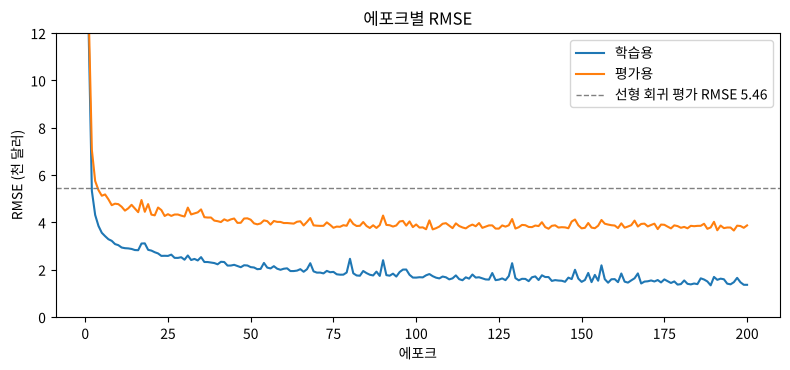

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(np.arange(1, epochs + 1), history[:, 0], label='학습용')
ax.plot(np.arange(1, epochs + 1), history[:, 1], label='평가용')
ax.axhline(5.457, color='gray', ls='--', lw=1, label='선형 회귀 평가 RMSE 5.46')
ax.set(xlabel='에포크', ylabel='RMSE (천 달러)', title='에포크별 RMSE', ylim=(0, 12))
ax.legend(); plt.tight_layout(); plt.show()

![회귀 학습 애니메이션](./images/anim_01_regression_training.gif)

## 9. 모델 평가 (교재 p.89)

In [12]:
model.eval()                                       # 평가 모드
with torch.no_grad():                              # 기울기 계산 끔
    test_preds = model(X_test_tensor).cpu().numpy().ravel()   # (127, 1) → (127,)

rmse_mlp = root_mean_squared_error(y_test, test_preds)   # 정답 단위(천 달러)의 평균 오차
r2_mlp = r2_score(y_test, test_preds)                    # 1 에 가까울수록 좋음, 0 = 평균으로 찍기
print(f'[보스톤 주택 가격 예측] PyTorch MLP 평가 RMSE: {rmse_mlp:.4f}  (R² {r2_mlp:.4f})')

for i in range(5):                                       # 실제값 vs 예측값
    print(f'  실제 {y_test.values[i]:5.1f}  예측 {test_preds[i]:5.1f}  오차 {test_preds[i] - y_test.values[i]:+5.1f}')

[보스톤 주택 가격 예측] PyTorch MLP 평가 RMSE: 3.8688  (R² 0.8168)
  실제  22.6  예측  22.9  오차  +0.3
  실제  50.0  예측  33.7  오차 -16.3
  실제  23.0  예측  24.5  오차  +1.5
  실제   8.3  예측  11.7  오차  +3.4
  실제  21.2  예측  20.3  오차  -0.9


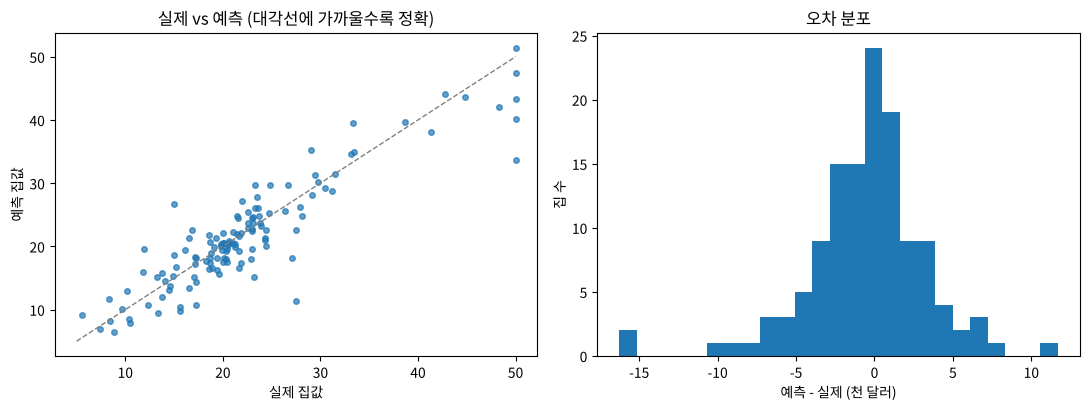

가장 크게 틀린 3 곳: [(50.0, 33.7), (27.5, 11.4), (15.0, 26.7)]


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(y_test, test_preds, s=16, alpha=0.7)
axes[0].plot([5, 50], [5, 50], color='gray', ls='--', lw=1)   # 완벽한 예측선
axes[0].set(xlabel='실제 집값', ylabel='예측 집값', title='실제 vs 예측 (대각선에 가까울수록 정확)')
resid = test_preds - y_test.values
axes[1].hist(resid, bins=25)
axes[1].set(xlabel='예측 - 실제 (천 달러)', ylabel='집 수', title='오차 분포')
plt.tight_layout(); plt.show()

big = np.argsort(-np.abs(resid))[:3]                       # 가장 크게 틀린 3 곳
print('가장 크게 틀린 3 곳:', [(float(y_test.values[i]), round(float(test_preds[i]), 1)) for i in big])

결과 해석
- 평가 RMSE **3.869** = 평균적으로 **약 3,870 달러** 빗나간다. R² 0.817 은 집값 변동의 82% 를 설명한다는 뜻(평균으로 찍으면 0).
- 학습 RMSE 1.358 vs 평가 3.869 — 학습용에 훨씬 잘 맞는다(약 3 배 차이, 10-5 에서 더 자세히).
- 가장 크게 틀린 곳은 **실제 50.0 → 예측 33.7**. 50 은 '50 이상' 을 잘라 기록한 값이라 실제 집값은 더 높을 수 있고, 모델이 맞히기 어려운 데이터다.

## 10. 비교 실험

같은 시드 · 같은 구조에서 조건만 바꿔 처음부터 다시 학습하는 함수를 만든다.

In [14]:
def train_model(lr=0.005, batch_size=16, epochs=200, scaled=True, unsqueeze=True, seed=SEED):
    """조건을 바꿔 처음부터 학습 → 에포크별 (학습 RMSE, 평가 RMSE) 배열"""
    Xtr = X_train_tensor if scaled else torch.tensor(X_train.values, dtype=torch.float32).to(device)
    Xte = X_test_tensor if scaled else torch.tensor(X_test.values, dtype=torch.float32).to(device)
    torch.manual_seed(seed)                                    # 같은 초기 가중치
    m = make_model()
    opt = optim.Adam(m.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(Xtr, y_train_tensor), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))   # 같은 섞는 순서
    hist = []
    for _ in range(epochs):
        m.train()
        for bx, by in loader:
            opt.zero_grad()
            target = by.unsqueeze(1) if unsqueeze else by       # 10-7 실수 재현용
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')                 # 모양이 다를 때 나오는 경고는 아래에서 따로 확인
                loss = criterion(m(bx), target)
            loss.backward()
            opt.step()
        hist.append((rmse_of(m, Xtr, y_train_tensor), rmse_of(m, Xte, y_test_tensor)))
    return np.array(hist)

def report(name, h):
    best = h[:, 1].argmin()
    print(f'{name:24s} | 마지막: 학습 {h[-1, 0]:.3f} · 평가 {h[-1, 1]:.3f}'
          f' | 평가 최저 {h[best, 1]:.3f} @ {best + 1} 에포크')

base = train_model()                 # 기본 조건 다시 학습 (8 절과 같은 값인지 확인)
report('기본 (lr 0.005 · 배치 16)', base)

기본 (lr 0.005 · 배치 16)    | 마지막: 학습 1.358 · 평가 3.869 | 평가 최저 3.652 @ 196 에포크


### 10-1. 기준 모델 — 평균으로 찍기 · 선형 회귀 · 랜덤 포레스트

In [15]:
mean_pred = np.full(len(y_test), y_train.mean())                   # 학습용 평균으로 모두 예측
lin = LinearRegression().fit(X_train_scaled, y_train)               # 은닉층 없는 퍼셉트론 1 개와 같은 모양
rf = RandomForestRegressor(random_state=0).fit(X_train, y_train)    # 트리 모델은 표준화 불필요

baselines = {
    '평균으로 찍기': mean_pred,
    '선형 회귀': lin.predict(X_test_scaled),
    '랜덤 포레스트': rf.predict(X_test),
    'MLP (이 노트)': test_preds,
}
for name, pred in baselines.items():
    print(f'{name:10s} 평가 RMSE {root_mean_squared_error(y_test, pred):6.3f}   R² {r2_score(y_test, pred):6.3f}')

평균으로 찍기    평가 RMSE  9.044   R² -0.001
선형 회귀      평가 RMSE  5.457   R²  0.635
랜덤 포레스트    평가 RMSE  4.072   R²  0.797
MLP (이 노트) 평가 RMSE  3.869   R²  0.817


![ReLU 곡선 애니메이션](./images/anim_02_relu_curve.gif)

왜 MLP 가 선형 회귀보다 나은지 — 특성 **`lstat` 하나만** 넣고 같은 구조(1 → 64 → 32 → 1)로 학습해 봤다. 선형 회귀는 직선 하나라 lstat 이 30% 를 넘으면 집값을 0 근처로 예측하지만(평가 RMSE 6.66), ReLU 뉴런들이 꺾인 직선을 이어 붙여 **곡선** 을 만들면서 5.79 까지 내려간다.

### 10-2. 학습률 — 메모의 0.01 vs 필기의 0.005 vs 0.001

In [16]:
lr_hist = {lr: (base if lr == 0.005 else train_model(lr=lr)) for lr in [0.001, 0.005, 0.01]}
for lr, h in lr_hist.items():
    report(f'lr {lr}', h)

lr 0.001                 | 마지막: 학습 1.756 · 평가 3.953 | 평가 최저 3.893 @ 199 에포크
lr 0.005                 | 마지막: 학습 1.358 · 평가 3.869 | 평가 최저 3.652 @ 196 에포크
lr 0.01                  | 마지막: 학습 1.241 · 평가 4.779 | 평가 최저 3.977 @ 42 에포크


![학습률 비교 애니메이션](./images/anim_03_learning_rate.gif)

### 10-3. 미니배치 16 vs 배치 학습(379 = 전체)

In [17]:
full_batch = train_model(batch_size=len(train_dataset))   # 1 에포크에 업데이트 1 번 → 200 번
report('배치 학습 (업데이트 200 번)', full_batch)
report('미니배치 16 (업데이트 4,800 번)', base)

배치 학습 (업데이트 200 번)       | 마지막: 학습 2.830 · 평가 4.635 | 평가 최저 4.635 @ 200 에포크
미니배치 16 (업데이트 4,800 번)   | 마지막: 학습 1.358 · 평가 3.869 | 평가 최저 3.652 @ 196 에포크


### 10-4. 표준화를 빼면?

In [18]:
no_scale = train_model(scaled=False)
report('표준화 X', no_scale)
report('표준화 O', base)

표준화 X                    | 마지막: 학습 3.015 · 평가 5.377 | 평가 최저 4.694 @ 99 에포크
표준화 O                    | 마지막: 학습 1.358 · 평가 3.869 | 평가 최저 3.652 @ 196 에포크


### 10-5. 오래 학습하면 — 1000 에포크

In [19]:
long_run = train_model(epochs=1000)
report('1000 에포크', long_run)

1000 에포크                 | 마지막: 학습 0.455 · 평가 3.793 | 평가 최저 3.412 @ 353 에포크


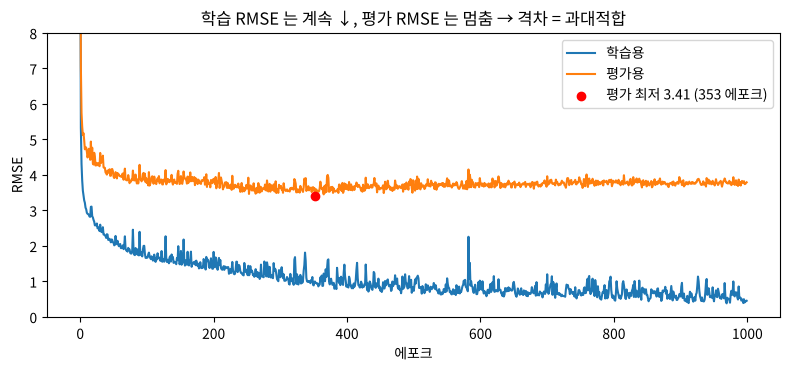

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(long_run[:, 0], label='학습용')
ax.plot(long_run[:, 1], label='평가용')
b = long_run[:, 1].argmin()
ax.scatter([b], [long_run[b, 1]], color='red', zorder=5, label=f'평가 최저 {long_run[b, 1]:.2f} ({b + 1} 에포크)')
ax.set(xlabel='에포크', ylabel='RMSE', ylim=(0, 8), title='학습 RMSE 는 계속 ↓, 평가 RMSE 는 멈춤 → 격차 = 과대적합')
ax.legend(); plt.tight_layout(); plt.show()

![과대적합 애니메이션](./images/anim_04_overfitting.gif)

### 10-6. 시드만 바꾸면?

In [21]:
seed_hist = {s: (base if s == SEED else train_model(seed=s)) for s in [0, 1, SEED]}
for s, h in seed_hist.items():
    report(f'seed {s}', h)

seed 0                   | 마지막: 학습 1.428 · 평가 3.980 | 평가 최저 3.908 @ 185 에포크
seed 1                   | 마지막: 학습 1.271 · 평가 4.032 | 평가 최저 3.750 @ 103 에포크
seed 42                  | 마지막: 학습 1.358 · 평가 3.869 | 평가 최저 3.652 @ 196 에포크


### 10-7. 자주 하는 실수 — 정답 `unsqueeze(1)` 를 빼먹으면

In [22]:
bx, by = next(iter(train_loader))
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always')
    wrong = criterion(model(bx), by)                 # 예측 (16, 1) · 정답 (16,)
    right = criterion(model(bx), by.unsqueeze(1))    # 예측 (16, 1) · 정답 (16, 1)
print(f'올바른 MSE {right.item():.3f} · 잘못된 MSE {wrong.item():.3f}  ← 에러 없이 경고만')
print('경고:', str(w[0].message)[:95], '…')

bug = train_model(unsqueeze=False)
report('unsqueeze 빠짐', bug)

올바른 MSE 2.220 · 잘못된 MSE 135.763  ← 에러 없이 경고만
경고: Using a target size (torch.Size([16])) that is different to the input size (torch.Size([16, 1]) …


unsqueeze 빠짐             | 마지막: 학습 9.096 · 평가 8.820 | 평가 최저 7.908 @ 80 에포크


![모양 실수 애니메이션](./images/anim_05_shape_bug.gif)

결과 해석
- **기준 모델** : 평균으로 찍기 9.04 → 선형 회귀 5.46 → 랜덤 포레스트 4.07 → **MLP 3.87**. 타이타닉 · 붓꽃과 달리 여기서는 은닉층이 확실히 도움이 됐다 — `lstat` · `rm` 과 집값의 관계가 곡선이라서(🎬 anim_02).
- **학습률** : 메모의 0.01 은 42 에포크에 평가 최저(3.98)를 찍고 200 에포크엔 4.78 까지 나빠졌다. 너무 빨리 학습용에 맞춰진다. 0.001 은 3.95 로 느리지만 안정적. 필기의 0.005 가 이 세 개 중 가장 좋았다.
- **배치 학습** : 업데이트가 200 번뿐이라 학습 RMSE 2.83 으로 덜 학습 → 평가 4.64.
- **표준화 X** : 평가 5.38 (최저 4.69). `tax`(수백) · `b`(수백) 같은 큰 특성 때문에 학습이 들쭉날쭉해진다.
- **1000 에포크** : 학습 RMSE 0.455 까지 내려가지만 평가는 353 에포크 3.41 에서 멈추고 3.79 로 끝난다 → 학습 · 평가 격차 8 배, **과대적합**.
- **시드** : 같은 조건인데 3.87 · 3.98 · 4.03 — 시드만 바꿔도 ±0.1 정도 흔들린다. 필기의 4.1572 도 이 범위 안. 모델끼리 0.1 차이는 '이겼다' 고 말하기 어렵다.
- **unsqueeze 빠짐** : (16, 1) 과 (16,) 이 브로드캐스팅되어 (16, 16) 의 모든 쌍 차이를 평균 → MSE 2.2 가 **135.8** 로. 에러 없이 학습은 되지만 평가 RMSE 8.82 — **평균으로 찍기(9.04)와 거의 같다**. 예측이 집마다 거의 같은 값(평균 20.6 · 표준편차 0.8)으로 몰린다(🎬 anim_05).

> **📝 고친 부분** — 교재 p.89 `criterion(test_preds, y_test)` 도 `y_test` 가 (N,) 면 같은 문제가 생긴다(Day 035 에서 확인). 필기처럼 sklearn `root_mean_squared_error(y_test, test_preds)` 를 쓰면 (N,) · (N, 1) 을 알아서 맞춰 줘서 안전하다.

## 📝 고친 부분 정리

| 위치 | 원래 | 고친 내용 |
|---|---|---|
| 필기 주석 | `cput` | cpu |
| 필기 import | `from torch.cuda import is_available` (안 씀) | 삭제 |
| 필기 | `drive.mount` · 드라이브 경로 · `display(df)` | 같은 폴더 CSV · `df.head()` |
| 필기 | 시드 없음 (RMSE 4.1572 재현 불가) | `torch.manual_seed` · DataLoader `generator` |
| 필기 주석 | `[은닉층2]` · `[출력층]` | [은닉층1 → 은닉층2] · [은닉층2 → 출력층] |
| 필기 | `epoch_loss / len(train_loader)` | 마지막 배치 11 개라 전체 MSE 와 약간 다름 → 에포크 끝에 전체로 다시 계산 |
| 필기 | 평가 RMSE 한 번만 | 에포크별 학습 · 평가 RMSE, R², 실제 vs 예측 그림, 기준 모델 비교 |
| 필기 | `test_preds` 모양 (127, 1) | `.ravel()` 로 1 차원 |
| 메모 p.1 | `X_train: 10개의 컬럼` | 보스턴은 **13 개** (10 개는 타이타닉) |
| 메모 p.1 | 모든 뉴런이 같은 `W1 … W10` | 뉴런마다 다른 가중치 $W_{j1} \dots W_{j13}$ |
| 메모 p.2 | `lr=0.01` | 필기 코드는 0.005 (10-2 비교) |